# Data Mining Project

### TASK: Classification by Decision Tree
* #### Classification of at least 1 target variable of your choice:

  - You should discuss the choice of the attributes and identify the best parameter
    configurations (e.g. gain criterion for trees, best k for KNN etc.).
  - Discussion
  - Evaluate the quantitative performance of the algorithms w.r.t. confusion matrix, accuracy, precision, recall, F1, ROC curve
  - Discuss some insight (e.g. try to interpret the tree(s))
  - Which is the best algorithm? Best can be studied w.r.t. the performance evaluation or other preferred point of view;

### Informazioni Generali
* **Corso:** Data Mining
* **Università:** Università di Pisa
* **Anno Accademico:** 2024/2025

### Autore
* **Studente:** Giuseppe Muschetta

### Dataset Utilizzato
* **Nome:** IMDb Dataset (Data Matrix)
* **Descrizione:** Dataset consisting of 21909 points in 23 dimensions

In [1]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [19]:
# Global style setting for Seaborn and matplotlib plots
plt.style.use("dark_background")
sns.set_theme(
    style="darkgrid",
    context="notebook",
    palette="icefire",  # rocket, mako, crest, vlag, flare
    font="sans-serif",
    font_scale=1.1
)

# Other palette examples:
# dark mode: icefire, rocket, mako, crest, vlag, flare
# white theme: viridis, magma, plasma, inferno, cividis,

# Ottimizzazione dei caratteri (solo se vuoi)
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.edgecolor'] = 'white'
plt.rcParams['axes.labelcolor'] = 'white'
plt.rcParams['xtick.color'] = 'lightgray'
plt.rcParams['ytick.color'] = 'lightgray'
plt.rcParams['text.color'] = 'white'
plt.rcParams['figure.facecolor'] = '#111111'
plt.rcParams['axes.facecolor'] = '#111111'
plt.rcParams['savefig.facecolor'] = '#111111'

In [3]:
# Create Directory for Plots ---
# To keep our project organized, we'll save all generated plots to a specific
# directory. This code creates a 'plots' directory if it doesn't already exist.

plots_dir = 'plots_classification/decision_tree/'

if not os.path.exists(plots_dir):
    os.makedirs(plots_dir, exist_ok=True)
    print(f"Directory {plots_dir} created successfully.")
else:
    print(f"Directory {plots_dir} already exists.")

# Load the dataset ---
# Load the dataset from the provided CSV file into a pandas DataFrame, which is
# the primary data structure we will use for our analysis.

# Define the file path
dataset_dir = 'dataset/'
dataset_train = 'train_prepared.csv'
dataset_test = 'test_prepared.csv'

# Load the data
try:
    df_train = pd.read_csv(dataset_dir + dataset_train)
    print(f"dataset '{dataset_train}' loaded successfully.")
    print(f"The dataset contains {df_train.shape[0]} rows and {df_train.shape[1]} columns.")
    df_test = pd.read_csv(dataset_dir + dataset_test)
    print(f"dataset '{dataset_test}' loaded successfully.")
    print(f"The dataset contains {df_test.shape[0]} rows and {df_test.shape[1]} columns.")
except FileNotFoundError:
    print(f"Error: The dataset in the dir '{dataset_dir}' was not found. Please check the file path.")
    exit(1)


Directory plots_classification/decision_tree/ already exists.
dataset 'train_prepared.csv' loaded successfully.
The dataset contains 15609 rows and 55 columns.
dataset 'test_prepared.csv' loaded successfully.
The dataset contains 5478 rows and 55 columns.


In [4]:
df_train

,originalTitle,startYear,endYear,runtimeMinutes,awardWins,numVotes,totalImages,totalVideos,totalCredits,criticReviewsTotal,...,awardWins_proc,numVotes_proc,totalImages_proc,totalVideos_proc,runtimeMinutes_proc,totalCredits_proc,criticReviewsTotal_proc,awardNominationsExcludeWins_proc,numRegions_proc,userReviewsTotal_proc
0,Neogenic Nightmare Chapter 3: Hydro-Man,1995,\N,58,0,779,1,0,21,1,...,-0.33267,1.465542,-0.510552,-0.277418,0.236295,-0.367632,0.264517,-0.316269,-0.661879,-0.648047
1,Looping,1982,\N,58,0,11,1,0,1,0,...,-0.33267,-0.906068,-0.510552,-0.277418,0.236295,-2.524145,-0.517037,-0.316269,-0.661879,-0.648047
2,Idealnaya para,1992,\N,58,0,38,1,0,24,0,...,-0.33267,-0.236435,-0.510552,-0.277418,0.236295,-0.252666,-0.517037,-0.316269,-0.661879,-0.015936
3,MasterChef Celebrity México,2021,\N,58,0,15,22,0,56,0,...,-0.33267,-0.742626,1.535001,-0.277418,0.236295,0.488544,-0.517037,-0.316269,-0.661879,-0.648047
4,Lightdance,1995,\N,34,0,14,1,0,0,0,...,-0.33267,-0.779293,-0.510552,-0.277418,-0.452128,-3.147517,-0.517037,-0.316269,-0.661879,-0.015936
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15604,Caprices,1942,\N,58,0,73,4,0,45,1,...,-0.33267,0.127457,0.256875,-0.277418,0.236295,0.295718,0.264517,-0.316269,2.187287,0.819669
15605,Haar Jeet,1990,\N,58,0,15,2,0,22,0,...,-0.33267,-0.742626,-0.170960,-0.277418,0.236295,-0.327654,-0.517037,-0.316269,-0.661879,-0.015936
15606,Kotigobba 3,2021,\N,140,0,2560,39,3,129,0,...,-0.33267,2.140973,1.998481,3.823313,1.384864,1.230032,-0.517037,3.308314,0.891610,2.919497
15607,Ator l'invincibile,1982,\N,58,0,3011,52,1,53,55,...,-0.33267,2.233128,2.234174,1.772947,0.236295,0.439920,4.021721,-0.316269,3.018445,3.070437


In [5]:
df_train.info(verbose=True, memory_usage='deep', show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15609 entries, 0 to 15608
Data columns (total 55 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   originalTitle                     15609 non-null  object 
 1   startYear                         15609 non-null  int64  
 2   endYear                           15609 non-null  object 
 3   runtimeMinutes                    15609 non-null  int64  
 4   awardWins                         15609 non-null  int64  
 5   numVotes                          15609 non-null  int64  
 6   totalImages                       15609 non-null  int64  
 7   totalVideos                       15609 non-null  int64  
 8   totalCredits                      15609 non-null  int64  
 9   criticReviewsTotal                15609 non-null  int64  
 10  awardNominationsExcludeWins       15609 non-null  int64  
 11  numRegions                        15609 non-null  int64  
 12  user

#### Valutazione della variabile Target

--- Class Distribution for 'rating' (3 Tiers) ---

Counts:
rating_encoded
Good       6851
Poor       4419
Average    4339
Name: count, dtype: int64

Percentages:
rating_encoded
Good       43.89 %
Poor       28.31 %
Average     27.8 %
Name: proportion, dtype: object


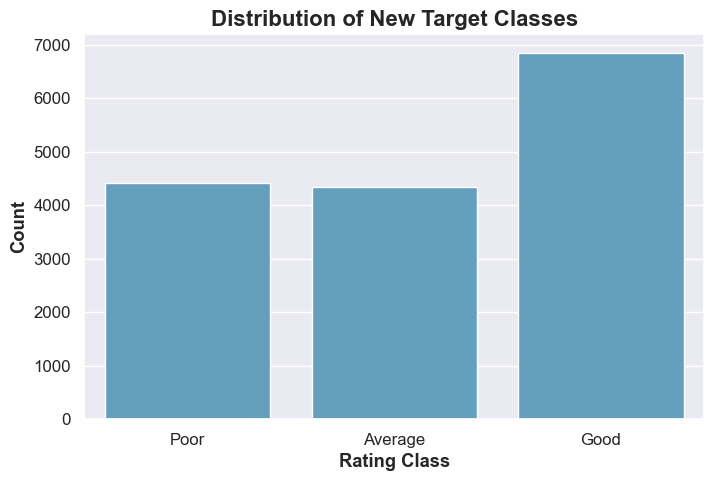

In [6]:
# --- Calculate Class Counts for the 3-Tier Rating System ---

def assign_rating_class(encoded_rating):
    """Groups the 10 encoded ratings into 3 final classes."""
    if encoded_rating <= 5:  # Original ratings up to 6.0
        return 'Poor'
    elif encoded_rating <= 6: # Original ratings from 6.1 to 7.0
        return 'Average'
    else:  # Original ratings from 7.1 to 10.0
        return 'Good'

# Create a temporary column to see the distribution
# We will make this permanent in the next step
temp_binned_col = df_train['rating_encoded'].apply(assign_rating_class)

# Calculate and print the counts and percentages for each class
class_distribution = temp_binned_col.value_counts()
class_percentages = temp_binned_col.value_counts(normalize=True) * 100

print("--- Class Distribution for 'rating' (3 Tiers) ---")
print("\nCounts:")
print(class_distribution)
print("\nPercentages:")
print(class_percentages.round(2).astype(str) + ' %')

# Plotting the distribution for a clear visual
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.barplot(x=class_distribution.index, y=class_distribution.values, order=['Poor', 'Average', 'Good'])
plt.title('Distribution of New Target Classes', fontsize=16, weight='bold')
plt.ylabel('Count')
plt.xlabel('Rating Class')
plt.savefig(f'{plots_dir}dt_rating_class_distribution.png', dpi=300)
plt.show()

#### Classificazione con Decision Tree

In [7]:
# --- 3.1. Target Variable and Feature Separation ---

# We will now make the creation of our target variable, 'rating_binned', permanent.
# The function defined previously will be applied to both the training and testing DataFrames.

def assign_rating_class(encoded_rating):
    """Groups the 10 encoded ratings into 3 final classes."""
    if encoded_rating <= 5:    # Corresponds to original ratings <= 6.0
        return 0 #'Poor'
    elif encoded_rating == 6:  # Corresponds to original ratings 6.1-7.0
        return 1 #'Average'
    else:                      # Corresponds to original ratings >= 7.1
        return 2 #'Good'

# Apply the function to create the target column
df_train['rating_binned'] = df_train['rating_encoded'].apply(assign_rating_class)
df_test['rating_binned'] = df_test['rating_encoded'].apply(assign_rating_class)

# Define the class names for later plotting
class_names = ['Poor', 'Average', 'Good']

print("Target variable 'rating_binned' created successfully.")
print("\nTrain set distribution:")
print(df_train['rating_binned'].value_counts())
print("\nTest set distribution:")
print(df_test['rating_binned'].value_counts())

Target variable 'rating_binned' created successfully.

Train set distribution:
rating_binned
2    6851
0    4419
1    4339
Name: count, dtype: int64

Test set distribution:
rating_binned
2    2414
0    1542
1    1522
Name: count, dtype: int64


In [8]:
# --- Separate Features (X) and Target (y) ---

# We define the feature matrix 'X' by dropping columns related to the target variable.
# The original 'averageRating' and the identifier 'tconst' were already removed
# during the preprocessing phase that created the '_prepared.csv' files.

# List of columns to drop to create the feature set
columns_to_drop = ['rating_encoded', 'rating_binned', 'originalTitle', 'endYear', 'startYear',
                   'runtimeMinutes', 'awardWins', 'numVotes', 'totalImages', 'totalVideos', 'totalCredits',
                   'criticReviewsTotal', 'awardNominationsExcludeWins', 'numRegions', 'userReviewsTotal']

# We add a check to ensure the columns exist before dropping, to prevent future errors
existing_columns_to_drop = [col for col in columns_to_drop if col in df_train.columns]

X_train = df_train.drop(columns=existing_columns_to_drop)
y_train = df_train['rating_binned']

X_test = df_test.drop(columns=existing_columns_to_drop)
y_test = df_test['rating_binned']

print("Features and target separated.")
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

# Let's check the features
print("\nFeatures being used for training:")
print(X_train.columns.tolist())

Features and target separated.
X_train shape: (15609, 41)
y_train shape: (15609,)
X_test shape: (5478, 41)
y_test shape: (5478,)

Features being used for training:
['titleType_movie', 'titleType_short', 'titleType_tvEpisode', 'titleType_tvMiniSeries', 'titleType_tvMovie', 'titleType_tvSeries', 'titleType_tvShort', 'titleType_tvSpecial', 'titleType_video', 'titleType_videoGame', 'genres_Drama', 'genres_Comedy', 'genres_Short', 'genres_Action', 'genres_Documentary', 'genres_Crime', 'genres_Adventure', 'genres_Animation', 'genres_Romance', 'genres_Family', 'countryOfOrigin_US', 'countryOfOrigin_GB', 'countryOfOrigin_JP', 'countryOfOrigin_FR', 'countryOfOrigin_CA', 'countryOfOrigin_IN', 'countryOfOrigin_DE', 'countryOfOrigin_IT', 'countryOfOrigin_ES', 'countryOfOrigin_AU', 'startYear_proc', 'awardWins_proc', 'numVotes_proc', 'totalImages_proc', 'totalVideos_proc', 'runtimeMinutes_proc', 'totalCredits_proc', 'criticReviewsTotal_proc', 'awardNominationsExcludeWins_proc', 'numRegions_proc', '

### Model 1: Decision Tree
* Our first model is the Decision Tree.
* Decision Trees are powerful non-parametric models that partition the feature space into a set of rectangles and fit a simple model in each one.
* They are highly interpretable.
#### **Steps:**
 1. Train a baseline Decision Tree classifier with default parameters.
 2. Evaluate its initial performance.
 3. Use `GridSearchCV` to find the optimal hyperparameters (`criterion`, `max_depth`, `min_samples_leaf`).
 4. Train the final, tuned model.
 5. Perform a thorough evaluation using a classification report, confusion matrix, and ROC curves.
 6. Discuss the results and try to interpret the model's logic.

--- Training Baseline Decision Tree ---

Baseline Model Performance:
Accuracy: 0.5015

Classification Report:
              precision    recall  f1-score   support

        Poor       0.48      0.49      0.49      1542
     Average       0.35      0.36      0.36      1522
        Good       0.61      0.59      0.60      2414

    accuracy                           0.50      5478
   macro avg       0.48      0.48      0.48      5478
weighted avg       0.50      0.50      0.50      5478



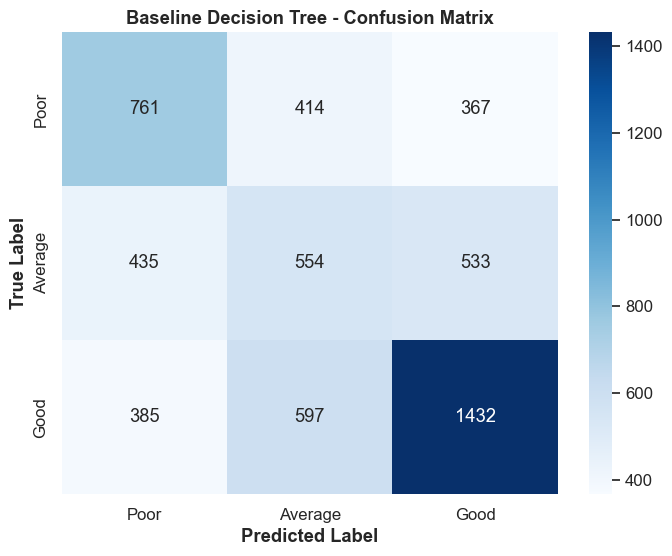

In [13]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import GridSearchCV

# --- Baseline Decision Tree ---
print("--- Training Baseline Decision Tree ---")

# 1. Instantiate the model with a random_state for reproducibility
baseline_tree = DecisionTreeClassifier(random_state=42, class_weight='balanced')

# 2. Train the model
baseline_tree.fit(X_train, y_train)

# 3. Make predictions
y_pred_baseline = baseline_tree.predict(X_test)

# 4. Evaluate the baseline model
print("\nBaseline Model Performance:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_baseline):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_baseline, target_names=class_names))

# Plotting the Confusion Matrix for the baseline model
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 6))
cm_baseline = confusion_matrix(y_test, y_pred_baseline)
sns.heatmap(cm_baseline, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Baseline Decision Tree - Confusion Matrix', weight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.savefig(f'{plots_dir}dt_baseline_confusion_matrix.png', dpi=300)
plt.show()

#### The baseline model achieves an accuracy of around 62.9%.
* It seems to perform reasonably well but shows signs of overfitting, which is common for decision trees with unlimited depth.
* For instance, it correctly predicts many 'Good' movies, but also misclassifies a significant number of 'Poor' and 'Average' movies.
* Now, we'll use GridSearchCV to find a more robust set of parameters to improve generalization.

--- Hyperparameter Tuning for Decision Tree ---
Fitting 5 folds for each of 4320 candidates, totalling 21600 fits

Best parameters found by GridSearchCV:
{'criterion': 'gini', 'max_depth': 15, 'max_features': None, 'max_leaf_nodes': 500, 'min_samples_leaf': 1, 'min_samples_split': 12}

--- Evaluating Tuned Decision Tree ---

Tuned Model Performance:
Accuracy: 0.5566

Classification Report:
              precision    recall  f1-score   support

        Poor       0.53      0.56      0.55      1542
     Average       0.40      0.27      0.32      1522
        Good       0.63      0.74      0.68      2414

    accuracy                           0.56      5478
   macro avg       0.52      0.52      0.51      5478
weighted avg       0.54      0.56      0.54      5478



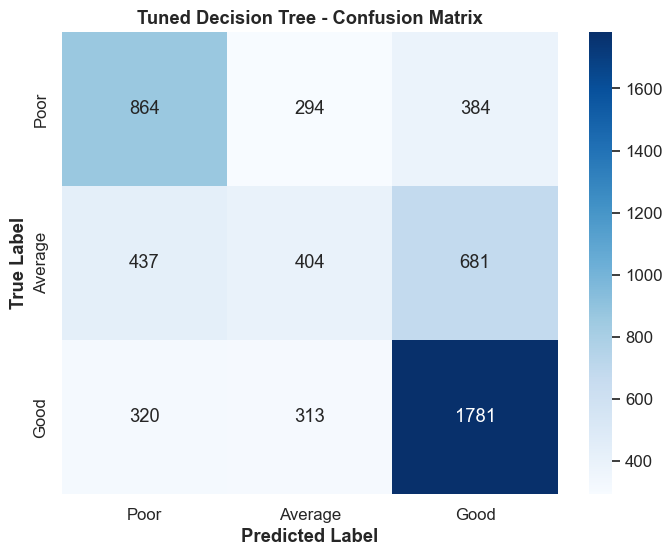

In [17]:
# --- Hyperparameter Tuning with GridSearchCV ---
print("--- Hyperparameter Tuning for Decision Tree ---")

# Define the parameter grid to search
# We test both 'gini' and 'entropy' criteria.
# We explore a range of depths to control the tree's complexity.
# We set a minimum number of samples per leaf to prevent overfitting on noise.
param_grid = {
   'criterion': ['gini', 'entropy'],
   'max_depth': [10, 15, 20, None],
   'min_samples_split': [2, 5, 7, 9, 12, 15],
   'min_samples_leaf': [1, 2, 5, 7, 9, 12],
   'max_features': ['sqrt', 'log2', None],
   'max_leaf_nodes': [100, 500, None],
}

# Instantiate the Decision Tree classifier
tree_grid = DecisionTreeClassifier(random_state=42)

# Instantiate GridSearchCV
# We use 5-fold cross-validation.
# 'n_jobs=-1' uses all available CPU cores to speed up the search.
# 'scoring='accuracy'' is the metric we want to optimize.
grid_search = GridSearchCV(estimator=tree_grid,
                           param_grid=param_grid,
                           cv=5,
                           n_jobs=-1,
                           verbose=1,
                           scoring='f1_macro',
)

# Fit GridSearchCV to the training data
grid_search.fit(X_train, y_train)

# Print the best parameters found
print("\nBest parameters found by GridSearchCV:")
print(grid_search.best_params_)

# Get the best estimator
best_tree = grid_search.best_estimator_

# --- Final Model Evaluation (Tuned Decision Tree) ---
print("\n--- Evaluating Tuned Decision Tree ---")

# Make predictions with the best model found
y_pred_tuned = best_tree.predict(X_test)

# Evaluate the tuned model
print("\nTuned Model Performance:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_tuned):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned, target_names=class_names))

# Plotting the Confusion Matrix for the tuned model
plt.figure(figsize=(8, 6))
cm_tuned = confusion_matrix(y_test, y_pred_tuned)
sns.heatmap(cm_tuned, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Tuned Decision Tree - Confusion Matrix', weight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.savefig(f'{plots_dir}dt_tuned_confusion_matrix.png', dpi=300)
plt.show()

* #### ROC Curve and AUC
* The Receiver Operating Characteristic (ROC) curve is a fundamental tool for evaluating classifier performance.
* It plots the True Positive Rate (TPR) against the False Positive Rate (FPR) at various threshold settings.
* The Area Under the Curve (AUC) provides a single scalar value summarizing the performance across all thresholds.
* For multi-class classification, we can plot ROC curves in a One-vs-Rest (OvR) fashion.
* This involves plotting a separate curve for each class, treating that class as the positive class and all other classes as the negative class.
* We will also compute the micro-average and macro-average ROC curves, which provide aggregated performance metrics.

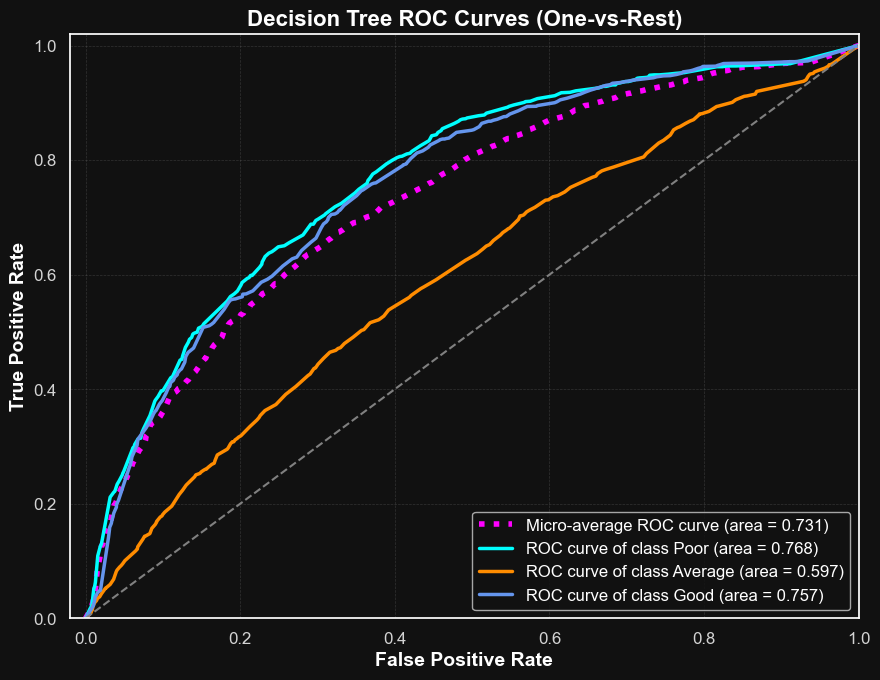

In [22]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
from itertools import cycle

# Binarize the output labels for ROC curve calculation
y_train_bin = label_binarize(y_train, classes=[0, 1, 2])
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_train_bin.shape[1]

# Get prediction probabilities for the test set
# ASSUMES 'best_tree' is your trained and tuned model
y_score = best_tree.predict_proba(X_test)

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute micro-average ROC curve and ROC area
fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), y_score.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# --- PLOT STYLING IMPROVEMENTS ---
plt.figure(figsize=(9, 7))

# Plot micro-average ROC
plt.plot(fpr["micro"], tpr["micro"],
         label=f'Micro-average ROC curve (area = {roc_auc["micro"]:0.3f})',
         color='magenta', linestyle=':', linewidth=4)

# Plot ROC for each class
colors = cycle(['#00FFFF', '#FF8C00', '#6495ED']) # Aqua, DarkOrange, CornflowerBlue hex codes
for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2.5,
             label=f'ROC curve of class {class_names[i]} (area = {roc_auc[i]:0.3f})')

# Plot the random classifier line (NOW VISIBLE!)
plt.plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--')

# Customize the plot for better readability
plt.xlim([-0.02, 1.0])
plt.ylim([0.0, 1.02])

# Add a subtle grid (NOW ELEGANT!)
plt.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.3)

# Labels, Title, and Legend
plt.xlabel('False Positive Rate', fontsize=14, weight='bold')
plt.ylabel('True Positive Rate', fontsize=14, weight='bold')
plt.title('Decision Tree ROC Curves (One-vs-Rest)', fontsize=16, weight='bold')
plt.legend(loc="lower right", prop={'size': 12})
plt.tight_layout()
plt.savefig(f'{plots_dir}dt_roc_curves_final.png', dpi=300)
plt.show()


#### Feature Importances

* Decision Trees can provide estimates of feature importance, which is a measure of how much each feature contributes to reducing impurity (e.g., Gini impurity) across the tree.
* This helps us understand which attributes the model found most predictive.

/var/folders/4l/s_d8z1kx7h762hwfcv4xhtsh0000gn/T/ipykernel_73803/1564418214.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='importance', y='feature', data=feature_importance_df.head(20), palette='icefire')


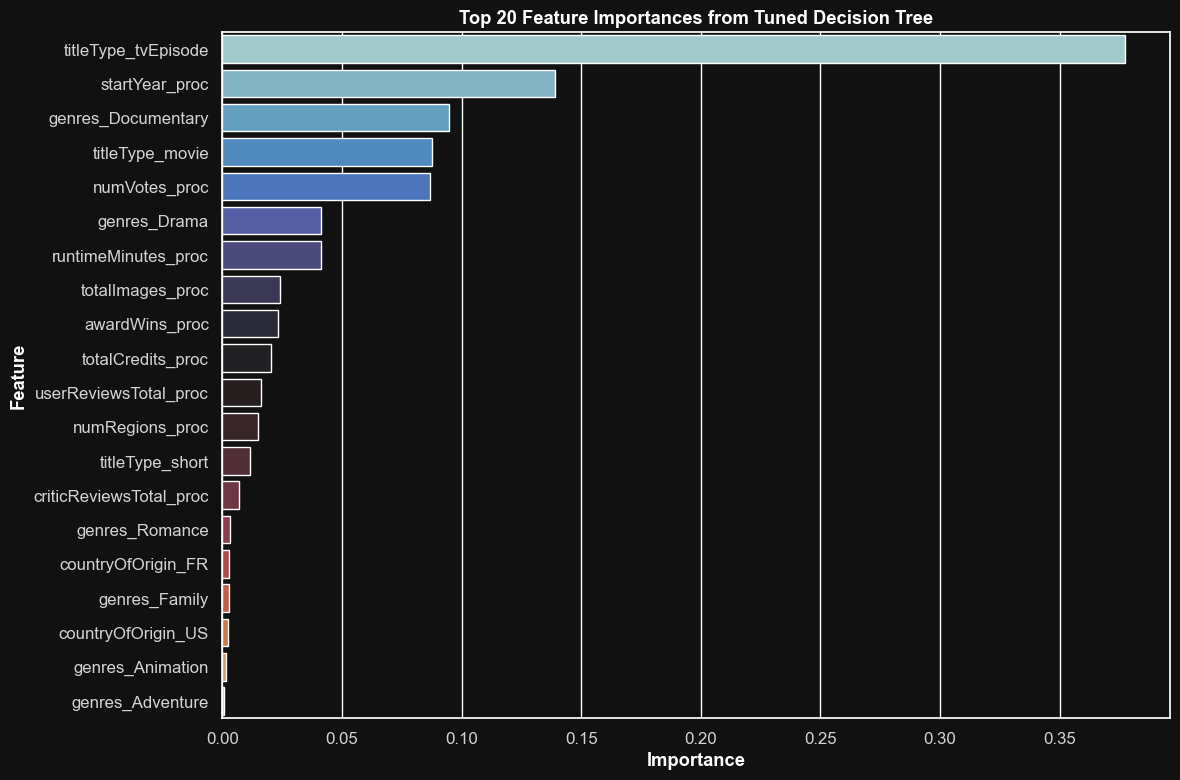

In [12]:
# Get feature importances from the tuned model
importances = best_tree.feature_importances_
feature_names = X_train.columns

# Create a DataFrame for visualization
feature_importance_df = pd.DataFrame({'feature': feature_names, 'importance': importances})
feature_importance_df = feature_importance_df.sort_values('importance', ascending=False)

# Plot the top 20 most important features
plt.figure(figsize=(12, 8))
sns.barplot(x='importance', y='feature', data=feature_importance_df.head(20), palette='icefire')
plt.title('Top 20 Feature Importances from Tuned Decision Tree', weight='bold')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.savefig(f'{plots_dir}dt_feature_importance.png', dpi=300)
plt.show()